In [19]:
%pylab inline
import gc
import fitsio
import treecorr
import numpy as np
import catutil
import matplotlib.lines as mlines

import astropy.table as astTable

Populating the interactive namespace from numpy and matplotlib


# Cosmic shear measurement on mocks

## merge 6 observational fields

In [2]:
nzs    =   4
pzname =   'dnnz' #demp/mizuki/dnnz
iblind =   0
def read_mock_catalog():
    '''
    Load mock catalog and divide into 4 redshift bins.
    Parameters:
    ---
    mbias: The multiplicative bias (including estimation bias and selection bias) [float]
    
    Returns:
    data:   S19A mock catalog (with m=mbias) [ndarray]
    '''
    # here I use the dnnz since the mock is based on dnnz
    pzDir   =   'wrkDir/catalog/'
    # 4 bins
    dataG  =   [[],[],[],[]]
    for fieldname in catutil.field_names:
        # mock catalog (will copy v2 to GW and idark)
        catFname=  'wrkDir/g3Sim/catalog_obs_reGaus_smallcat_xiangchong/%s.fits' %(fieldname)
        data   =   fitsio.read(catFname)
        # selection using measured photo-z (not the true source photo-z)
        pzsname=   os.path.join(pzDir,'%s_%s_zmask.fits' %(fieldname,pzname))
        for iz in range(nzs):
            zmsk   =   fitsio.read(pzsname)['%s_mask_%sbin' %(pzname,iz)]
            # merge observational fields
            dataG[iz].append(data[zmsk])
        gc.collect()
    dataG=[np.hstack(dataG[i]) for i in range(nzs)]
    print('number of galaxies in each bin:',len(dataG[0]),len(dataG[1]),len(dataG[2]),len(dataG[3]))
    return dataG

In [3]:
%%time
dataG=read_mock_catalog() #testing the spped

number of galaxies in each bin: 1778855 8665773 9547781 7432666
CPU times: user 3.2 s, sys: 19.8 s, total: 23 s
Wall time: 23.3 s


In [4]:
mrTab=astTable.Table.read('wrkDir/catalog/shear_biases_%s.csv'%pzname)
mrTab

m_shear_cat0,m_shear_cat1,m_shear_cat2,response,m_sel,a_sel,m_sel_err,a_sel_err
float64,float64,float64,float64,float64,float64,float64,float64
-0.09141873382555632,-0.04141986637719917,0.008576928651350645,0.8407182287610664,0.009205343535801429,0.0031953056659898005,0.0006539147131223044,0.000451824547471789
-0.10856406026726798,-0.05856519281891106,-0.008568397790361242,0.8469750725856124,0.01573986888212821,0.006766819785054489,0.0014204144687904687,0.0009344313797495946
-0.11036946813340669,-0.06037060068504935,-0.010373805656499539,0.8464418502264891,0.015100718683580937,0.008362438526165347,0.0019340869826879213,0.0011627008240484
-0.11541040947253108,-0.06541154202417392,-0.015414746995624005,0.8410178590969258,0.012108216412363197,0.008442651379087425,0.0021458840889916684,0.0011996138863263287


## Measuring correlations

In [5]:
def measure_cs(dataG,response=1.,mbias=0.):
    cor  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
    out={}
    for ii in range(nzs):
        g1I=(dataG[ii]['i_hsmshaperegauss_e1']/2./response[ii]-dataG[ii]['i_hsmshaperegauss_derived_shear_bias_c1'])/\
                (1+mbias[ii])
        g2I=(dataG[ii]['i_hsmshaperegauss_e2']/2./response[ii]-dataG[ii]['i_hsmshaperegauss_derived_shear_bias_c2'])/\
                (1+mbias[ii])
        catEi  =   treecorr.Catalog(g1=g1I,g2=-g2I,\
                                    ra=dataG[ii]['i_ra'],dec=dataG[ii]['i_dec'],\
                                    w=dataG[ii]['i_hsmshaperegauss_derived_weight'],ra_units='deg',dec_units='deg') 
        for jj in range(ii,nzs):
            g1J=(dataG[jj]['i_hsmshaperegauss_e1']/2./response[jj]-dataG[jj]['i_hsmshaperegauss_derived_shear_bias_c1'])/\
                    (1+mbias[jj])
            g2J=(dataG[jj]['i_hsmshaperegauss_e2']/2./response[jj]-dataG[jj]['i_hsmshaperegauss_derived_shear_bias_c2'])/\
                    (1+mbias[jj])
            
            
            catEj  =   treecorr.Catalog(g1=g1J,g2=-g2J,\
                                        ra=dataG[jj]['i_ra'],dec=dataG[jj]['i_dec'],\
                                        w=dataG[jj]['i_hsmshaperegauss_derived_weight'],ra_units='deg',dec_units='deg') 
            # correlation 
            cor.clear()
            cor.process(catEi,catEj)
            del catEj
            gc.collect()
            out.update({'%d%d'%(ii,jj):cor.copy()})
        del catEi
        gc.collect()
    return out

In [71]:
%%time
cors0=measure_cs(dataG,response=mrTab['response'],mbias=mrTab['m_shear_cat0']+mrTab['m_sel']) 

CPU times: user 54min 1s, sys: 22.1 s, total: 54min 23s
Wall time: 5min 29s


In [73]:
def plot_cosmicShear(cors):
    # make plot
    plt.close()
    fig = plt.figure(figsize=(8,8))
    for i in range(nzs):
        for j in range(i,nzs):
            ax = plt.subplot2grid((8, 8), (j*2, i*2), colspan=2,rowspan=2)
            ax.set_ylim(2e-7,2e-3)
            ax.set_title(r'$%d \times %d$' %(i+1,j+1),fontsize=15,y=1.0, pad=-15,x=0.8)
            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.grid()
            if i!=0:
                #ax.get_yaxis().set_visible(False)
                ax.set_yticks((1e-6,1e-5,1e-4,1e-3))
                ax.set_yticklabels(('','','',''))
                #ax.set_yticklabels(('$10^{-5}$','$10^{-4}$'))
            else:
                ax.set_yticks((1e-6,1e-5,1e-4,1e-3))
            if j!=nzs-1:
                #ax.get_xaxis().set_visible(False)
                ax.set_xticks((2,10,60))
                ax.set_xticklabels(('','',''))
            else:
                ax.set_xticks((2,10,60))
                ax.set_xticklabels(('2','10','60'))
            if i==0 and j==2:
                ax.set_ylabel(r'$\xi_{\pm}$')
            if j==nzs-1 and i==1:
                ax.set_xlabel(r'$\theta$ [arcmin]')
            ax.plot(cors['%d%d'%(i,j)].rnom,cors['%d%d'%(i,j)].xip,'+',color='red')
            ax.plot(cors['%d%d'%(i,j)].rnom,cors['%d%d'%(i,j)].xim,'.',color='blue')
    ax = plt.subplot2grid((8, 8), (0*2, 1*2), colspan=2,rowspan=2)
    ax.set_axis_off()
    leg1 = mlines.Line2D([], [], color='red', ls='-',label=r'$\xi_+$')
    leg2 = mlines.Line2D([], [], color='blue', ls='-',label=r'$\xi_-$')
    ll=ax.legend(handles=[leg1,leg2],loc='lower right',fontsize=18)
    ll.axes.set_title('blind-0',fontsize=18,pad=-18,weight='bold')
    return

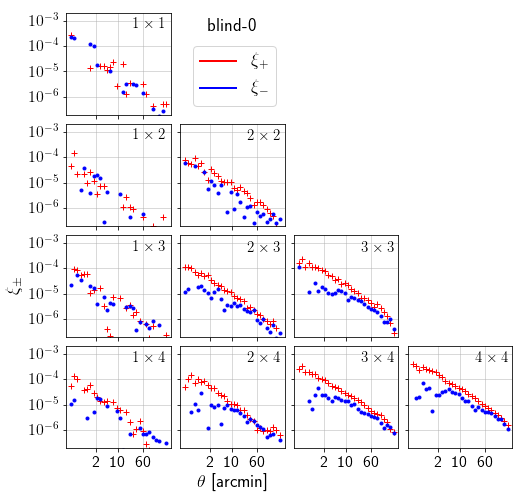

In [74]:
plot_cosmicShear(cors0)